In [1]:
import pickle
import numpy as np

In [2]:
with open('./Resources/UPDATED_NLP_COURSE/06-Deep-Learning/train_qa.txt', 'rb') as f:
    train_data = pickle.load(f)

with open('./Resources/UPDATED_NLP_COURSE/06-Deep-Learning/test_qa.txt', 'rb') as f:
    test_data = pickle.load(f)

In [3]:
type(train_data)

list

In [4]:
type(test_data)

list

In [5]:
len(train_data)

10000

In [6]:
len(test_data)

1000

In [7]:
train_data[0]

(['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.'],
 ['Is', 'Sandra', 'in', 'the', 'hallway', '?'],
 'no')

In [8]:
' '.join(train_data[0][0])

'Mary moved to the bathroom . Sandra journeyed to the bedroom .'

In [9]:
' '.join(train_data[0][1])

'Is Sandra in the hallway ?'

In [10]:
train_data[0][2]

'no'

In [11]:
all_data = train_data + test_data
len(all_data)

11000

In [12]:
vocab = set()

for story,question,answer in all_data:
    vocab = vocab.union(set(story))
    vocab = vocab.union(set(question))

In [13]:
vocab.add('no')
vocab.add('yes')

In [14]:
vocab

{'.',
 '?',
 'Daniel',
 'Is',
 'John',
 'Mary',
 'Sandra',
 'apple',
 'back',
 'bathroom',
 'bedroom',
 'discarded',
 'down',
 'dropped',
 'football',
 'garden',
 'got',
 'grabbed',
 'hallway',
 'in',
 'journeyed',
 'kitchen',
 'left',
 'milk',
 'moved',
 'no',
 'office',
 'picked',
 'put',
 'the',
 'there',
 'to',
 'took',
 'travelled',
 'up',
 'went',
 'yes'}

In [15]:
vocab_len = len(vocab)+1
vocab_len

38

In [16]:
all_data[0]

(['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.'],
 ['Is', 'Sandra', 'in', 'the', 'hallway', '?'],
 'no')

In [17]:
# LONGEST STORY

all_story_lens = [len(data[0]) for data in all_data]

In [18]:
max_story_len = max(all_story_lens)
max_story_len

156

In [19]:
max_question_len = max([len(data[1]) for data in all_data])
max_question_len

6

In [20]:
from keras.utils import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

In [21]:
# Exact vocabulary mapping saved in the course notebook for chatbot_10.h5.
# Fitting on a set changes token IDs between sessions and corrupts predictions.
checkpoint_word_index = {'.': 13, '?': 12, 'apple': 3, 'back': 18, 'bathroom': 23, 'bedroom': 29, 'daniel': 21, 'discarded': 5, 'down': 22, 'dropped': 4, 'football': 37, 'garden': 36, 'got': 34, 'grabbed': 15, 'hallway': 27, 'in': 8, 'is': 30, 'john': 10, 'journeyed': 35, 'kitchen': 11, 'left': 31, 'mary': 25, 'milk': 7, 'moved': 28, 'no': 6, 'office': 24, 'picked': 1, 'put': 33, 'sandra': 2, 'the': 32, 'there': 16, 'to': 14, 'took': 9, 'travelled': 20, 'up': 17, 'went': 26, 'yes': 19}
tokenizer = Tokenizer(filters='')
tokenizer.fit_on_texts([word for word, index in sorted(checkpoint_word_index.items(), key=lambda item: item[1])])
assert tokenizer.word_index == checkpoint_word_index


In [22]:
tokenizer.word_index

{'picked': 1,
 'sandra': 2,
 'apple': 3,
 'dropped': 4,
 'discarded': 5,
 'no': 6,
 'milk': 7,
 'in': 8,
 'took': 9,
 'john': 10,
 'kitchen': 11,
 '?': 12,
 '.': 13,
 'to': 14,
 'grabbed': 15,
 'there': 16,
 'up': 17,
 'back': 18,
 'yes': 19,
 'travelled': 20,
 'daniel': 21,
 'down': 22,
 'bathroom': 23,
 'office': 24,
 'mary': 25,
 'went': 26,
 'hallway': 27,
 'moved': 28,
 'bedroom': 29,
 'is': 30,
 'left': 31,
 'the': 32,
 'put': 33,
 'got': 34,
 'journeyed': 35,
 'garden': 36,
 'football': 37}

In [23]:
train_story_text = []
train_question_text = []
train_answers = []

In [24]:
for story,question,answer in train_data:
    train_story_text.append(story)
    train_question_text.append(question)
    train_answers.append(answer)

In [25]:
train_story_text

[['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.'],
 ['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.',
  'Mary',
  'went',
  'back',
  'to',
  'the',
  'bedroom',
  '.',
  'Daniel',
  'went',
  'back',
  'to',
  'the',
  'hallway',
  '.'],
 ['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.',
  'Mary',
  'went',
  'back',
  'to',
  'the',
  'bedroom',
  '.',
  'Daniel',
  'went',
  'back',
  'to',
  'the',
  'hallway',
  '.',
  'Sandra',
  'went',
  'to',
  'the',
  'kitchen',
  '.',
  'Daniel',
  'went',
  'back',
  'to',
  'the',
  'bathroom',
  '.'],
 ['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.',
  'Mary',
  'went',
  'back',
  'to',
  'the',
  'bedroom',
  '.',
  'Daniel',
  'went',
  'back',
  'to

In [26]:
train_story_seq = tokenizer.texts_to_sequences(train_story_text)

In [27]:
len(train_story_seq)

10000

In [28]:
len(train_story_text)

10000

In [29]:
train_story_seq

[[25, 28, 14, 32, 23, 13, 2, 35, 14, 32, 29, 13],
 [25,
  28,
  14,
  32,
  23,
  13,
  2,
  35,
  14,
  32,
  29,
  13,
  25,
  26,
  18,
  14,
  32,
  29,
  13,
  21,
  26,
  18,
  14,
  32,
  27,
  13],
 [25,
  28,
  14,
  32,
  23,
  13,
  2,
  35,
  14,
  32,
  29,
  13,
  25,
  26,
  18,
  14,
  32,
  29,
  13,
  21,
  26,
  18,
  14,
  32,
  27,
  13,
  2,
  26,
  14,
  32,
  11,
  13,
  21,
  26,
  18,
  14,
  32,
  23,
  13],
 [25,
  28,
  14,
  32,
  23,
  13,
  2,
  35,
  14,
  32,
  29,
  13,
  25,
  26,
  18,
  14,
  32,
  29,
  13,
  21,
  26,
  18,
  14,
  32,
  27,
  13,
  2,
  26,
  14,
  32,
  11,
  13,
  21,
  26,
  18,
  14,
  32,
  23,
  13,
  21,
  1,
  17,
  32,
  37,
  16,
  13,
  21,
  26,
  14,
  32,
  29,
  13],
 [25,
  28,
  14,
  32,
  23,
  13,
  2,
  35,
  14,
  32,
  29,
  13,
  25,
  26,
  18,
  14,
  32,
  29,
  13,
  21,
  26,
  18,
  14,
  32,
  27,
  13,
  2,
  26,
  14,
  32,
  11,
  13,
  21,
  26,
  18,
  14,
  32,
  23,
  13,
  21,
  1,
  17,
  

In [30]:
train_story_text

[['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.'],
 ['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.',
  'Mary',
  'went',
  'back',
  'to',
  'the',
  'bedroom',
  '.',
  'Daniel',
  'went',
  'back',
  'to',
  'the',
  'hallway',
  '.'],
 ['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.',
  'Mary',
  'went',
  'back',
  'to',
  'the',
  'bedroom',
  '.',
  'Daniel',
  'went',
  'back',
  'to',
  'the',
  'hallway',
  '.',
  'Sandra',
  'went',
  'to',
  'the',
  'kitchen',
  '.',
  'Daniel',
  'went',
  'back',
  'to',
  'the',
  'bathroom',
  '.'],
 ['Mary',
  'moved',
  'to',
  'the',
  'bathroom',
  '.',
  'Sandra',
  'journeyed',
  'to',
  'the',
  'bedroom',
  '.',
  'Mary',
  'went',
  'back',
  'to',
  'the',
  'bedroom',
  '.',
  'Daniel',
  'went',
  'back',
  'to

In [31]:
def vectorize_stories(data,word_index=None,max_story_len=max_story_len,max_question_len=max_question_len):

    if word_index is None:
        word_index = tokenizer.word_index

    # STORIES
    X = []
    # QUESTIONS Xq
    Xq = []
    # Y CORRECT ANSWER (yes/no)
    Y = []

    # for each story
    # [23,14,...]
    for story, question, answer in data:
        x = [word_index[word.lower()] for word in story]
        xq = [word_index[word.lower()] for word in question]
        y = np.zeros(len(word_index) + 1)
        y[word_index[answer]] = 1

        X.append(x) 
        Xq.append(xq)
        Y.append(y)
    return (pad_sequences(X, maxlen=max_story_len), pad_sequences(Xq, maxlen=max_question_len), np.array(Y))

In [32]:
inputs_train, queries_train, answers_train = vectorize_stories(train_data)

In [33]:
inputs_test, queries_test, answers_test = vectorize_stories(test_data)

In [34]:
inputs_test

array([[ 0,  0,  0, ..., 32, 29, 13],
       [ 0,  0,  0, ..., 32, 36, 13],
       [ 0,  0,  0, ..., 32, 36, 13],
       ...,
       [ 0,  0,  0, ..., 32,  3, 13],
       [ 0,  0,  0, ..., 32, 36, 13],
       [ 0,  0,  0, ...,  3, 16, 13]], dtype=int32)

In [35]:
answers_test

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [36]:
tokenizer.word_index['yes']

19

In [37]:
tokenizer.word_index['no']

6

In [38]:
sum(answers_test)

array([  0.,   0.,   0.,   0.,   0.,   0., 503.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 497.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
         0.,   0.,   0.,   0.,   0.])

In [39]:
from keras.models import Sequential, Model
from keras.layers import Embedding

In [40]:
from keras.layers import Input,Activation,Dense,Permute,Dropout,add,dot,concatenate,LSTM

In [41]:
# PLACEHOLDER shape = (max_story_len,batch_size)
input_sequence = Input(shape=(max_story_len,))
question = Input(shape=(max_question_len,))

In [42]:
# vocab len
vocab_size = len(vocab)+1

In [43]:
# INPUT ENCODER M
input_encoder_m = Sequential()
input_encoder_m.add(Embedding(input_dim=vocab_size,output_dim=64))
input_encoder_m.add(Dropout(0.3))

#OUTPUT
# (samples, story_maxlen, embedding_dim)

2026-11-07 22:40:09.616799: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4
2026-11-07 22:40:09.616844: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 24.00 GB
2026-11-07 22:40:09.616874: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 8.00 GB
I0000 00:00:1794071409.616907  717613 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794071409.616940  717613 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [44]:
# INPUT ENCODER C
input_encoder_c = Sequential()
input_encoder_c.add(Embedding(input_dim=vocab_size,output_dim=max_question_len))
input_encoder_c.add(Dropout(0.3))

#OUTPUT
# (samples, story_maxlen, max_question_len)

In [45]:
question_encoder = Sequential()
question_encoder.add(Embedding(input_dim=vocab_size,output_dim=64,input_length=max_question_len))
question_encoder.add(Dropout(0.3))

#OUTPUT
# (samples, question_maxlen, embedding_dim)

/Users/ankit/Workspace/Projects/ankit-github/AI-ML-DS/.venv/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [46]:
# ENCODED <-- ENCODER(INPUT)

input_encoded_m = input_encoder_m(input_sequence)
input_encoded_c = input_encoder_c(input_sequence)
question_encoded = question_encoder(question)

In [47]:
match = dot([input_encoded_m,question_encoded],axes =(2,2))
match = Activation('softmax')(match)


In [48]:
response = add([match,input_encoded_c])
response = Permute((2,1))(response)


In [49]:
answer = concatenate([response,question_encoded])
answer

<KerasTensor shape=(None, 6, 220), dtype=float32, sparse=False, ragged=False, name=keras_tensor_18>

In [50]:
answer = LSTM(32)(answer)
answer = Dropout(0.5)(answer)
answer = Dense(vocab_size)(answer) # (samples,vocab_size) # Yes/No
answer = Activation('softmax')(answer)

In [51]:
model = Model(inputs=[input_sequence,question],outputs=answer)
model.compile(optimizer='rmsprop',loss='categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 156)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 156, 64)   │      2,432 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_2        │ (None, 6, 64)     │      2,432 │ input_layer_1[0]… │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 156, 6)    │          0 │ sequential[0][0], │
│                     │                   │            │ sequential_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 156, 6)    │          0 │ dot[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential_1        │ (None, 156, 6)    │        228 │ input_layer[0][0] │
│ (Sequential)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 156, 6)    │          0 │ activation[0][0], │
│                     │                   │            │ sequential_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ permute (Permute)   │ (None, 6, 156)    │          0 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 6, 220)    │          0 │ permute[0][0],    │
│ (Concatenate)       │                   │            │ sequential_2[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │     32,384 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 38)        │      1,254 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 38)        │          0 │ dense[0][0]       │
│ (Activation)        │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 38,730 (151.29 KB)

 Trainable params: 38,730 (151.29 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
history = model.fit([inputs_train,queries_train],answers_train,batch_size=32,epochs=20,
                    validation_data=([inputs_test,queries_test],answers_test))


Epoch 1/20


2026-11-07 22:40:10.510958: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.4935 - loss: 0.8745 - val_accuracy: 0.5030 - val_loss: 0.6946
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.4974 - loss: 0.7056 - val_accuracy: 0.4970 - val_loss: 0.6948
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5020 - loss: 0.6977 - val_accuracy: 0.5030 - val_loss: 0.6933
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 0.4929 - loss: 0.6963 - val_accuracy: 0.5080 - val_loss: 0.6932
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5081 - loss: 0.6952 - val_accuracy: 0.5030 - val_loss: 0.6945
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.4974 - loss: 0.6956 - val_accuracy: 0.4970 - val_loss: 0.6936
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.4907 - loss: 0.6958 - val_accuracy: 0.5030 - val_loss: 0.6942
Epoch 8/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.4986 - loss: 0.6956 - val_accuracy: 0.503

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


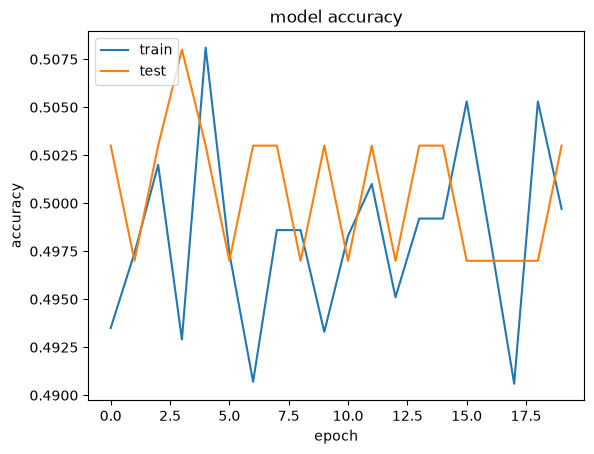

In [53]:
import matplotlib.pyplot as plt
%matplotlib inline
print(history.history.keys())
# summarize history for accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [54]:
# model.save('mybrandnewmodel.h5')

In [55]:
# Reload inputs with the checkpoint vocabulary, including when rerunning this cell.
inputs_test, queries_test, answers_test = vectorize_stories(test_data)
model.load_weights('./Resources/UPDATED_NLP_COURSE/06-Deep-Learning/chatbot_10.h5')

In [56]:
pred_results = model.predict(([inputs_test,queries_test]))

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [57]:
test_data

[(['Mary',
   'got',
   'the',
   'milk',
   'there',
   '.',
   'John',
   'moved',
   'to',
   'the',
   'bedroom',
   '.'],
  ['Is', 'John', 'in', 'the', 'kitchen', '?'],
  'no'),
 (['Mary',
   'got',
   'the',
   'milk',
   'there',
   '.',
   'John',
   'moved',
   'to',
   'the',
   'bedroom',
   '.',
   'Mary',
   'discarded',
   'the',
   'milk',
   '.',
   'John',
   'went',
   'to',
   'the',
   'garden',
   '.'],
  ['Is', 'John', 'in', 'the', 'kitchen', '?'],
  'no'),
 (['Mary',
   'got',
   'the',
   'milk',
   'there',
   '.',
   'John',
   'moved',
   'to',
   'the',
   'bedroom',
   '.',
   'Mary',
   'discarded',
   'the',
   'milk',
   '.',
   'John',
   'went',
   'to',
   'the',
   'garden',
   '.',
   'Daniel',
   'moved',
   'to',
   'the',
   'bedroom',
   '.',
   'Daniel',
   'went',
   'to',
   'the',
   'garden',
   '.'],
  ['Is', 'John', 'in', 'the', 'garden', '?'],
  'yes'),
 (['Mary',
   'got',
   'the',
   'milk',
   'there',
   '.',
   'John',
   'moved',


In [58]:
test_data[0][0]

['Mary',
 'got',
 'the',
 'milk',
 'there',
 '.',
 'John',
 'moved',
 'to',
 'the',
 'bedroom',
 '.']

In [59]:
test_data[0][1]

['Is', 'John', 'in', 'the', 'kitchen', '?']

In [60]:
test_data[0][2]

'no'

In [61]:
pred_results.shape

(1000, 38)

In [62]:
pred_results[0]

array([8.82675958e-14, 9.26844932e-14, 8.97197017e-14, 8.33775865e-14,
       9.40963141e-14, 8.75224033e-14, 9.99999642e-01, 1.06067275e-13,
       9.41244898e-14, 9.04801475e-14, 1.06623864e-13, 9.01433875e-14,
       9.43211031e-14, 1.00678519e-13, 8.31162396e-14, 8.40041266e-14,
       9.46128077e-14, 8.58945890e-14, 7.69565076e-14, 3.18596818e-07,
       9.46126315e-14, 8.01449158e-14, 1.01321363e-13, 8.03960034e-14,
       8.87438113e-14, 1.03005319e-13, 8.95593278e-14, 8.87922345e-14,
       7.54775338e-14, 7.74481797e-14, 8.43710410e-14, 9.07933939e-14,
       8.71223395e-14, 9.21361511e-14, 9.32485426e-14, 1.05032695e-13,
       8.36699281e-14, 8.96967776e-14], dtype=float32)

In [63]:
val_max = np.argmax(pred_results[0])
print(val_max)

6


In [64]:
k = tokenizer.index_word[int(val_max)]

In [65]:
k

'no'

In [66]:
pred_results[0][val_max]

np.float32(0.99999964)

In [67]:
vocab

{'.',
 '?',
 'Daniel',
 'Is',
 'John',
 'Mary',
 'Sandra',
 'apple',
 'back',
 'bathroom',
 'bedroom',
 'discarded',
 'down',
 'dropped',
 'football',
 'garden',
 'got',
 'grabbed',
 'hallway',
 'in',
 'journeyed',
 'kitchen',
 'left',
 'milk',
 'moved',
 'no',
 'office',
 'picked',
 'put',
 'the',
 'there',
 'to',
 'took',
 'travelled',
 'up',
 'went',
 'yes'}

In [68]:
my_story = "John left the kitchen . Sandra dropped the football in the garden ."

In [69]:
my_story.split()

['John',
 'left',
 'the',
 'kitchen',
 '.',
 'Sandra',
 'dropped',
 'the',
 'football',
 'in',
 'the',
 'garden',
 '.']

In [70]:
my_question = "Is the football in the garden ?"

In [71]:
my_question.split()

['Is', 'the', 'football', 'in', 'the', 'garden', '?']

In [72]:
mydata = [(my_story.split(), my_question.split(),'yes')]
mydata

[(['John',
   'left',
   'the',
   'kitchen',
   '.',
   'Sandra',
   'dropped',
   'the',
   'football',
   'in',
   'the',
   'garden',
   '.'],
  ['Is', 'the', 'football', 'in', 'the', 'garden', '?'],
  'yes')]

In [73]:
my_story, my_ques, my_ans = vectorize_stories(mydata)

In [74]:
my_story

array([[ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0, 10,
        31, 32, 11, 13,  2,  4, 32, 37,  8, 32, 36, 13]], dtype=int32)

In [75]:
my_ques

array([[32, 37,  8, 32, 36, 12]], dtype=int32)

In [76]:
my_ans

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0.]])

In [77]:
pred_results = model.predict([my_story, my_ques])
val_max = np.argmax(pred_results[0])
for key,val in tokenizer.word_index.items():
    if val == val_max:
        k = key

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 824ms/step


In [78]:
k

'yes'

In [79]:
pred_results[0][val_max]

np.float32(0.9850912)